In [ ]:
# ==============================================================================
# TRACCIATO DI ANALISI: Dataset 2 – California Housing (Census 1990)
# ==============================================================================
# OBIETTIVO: Prevedere il valore medio delle abitazioni (MedHouseVal) a livello 
#            di blocco censuario (block group) basandosi su fattori demografici, 
#            economici e geografici.
#
# TARGET: MedHouseVal (espresso in centinaia di migliaia di $, es. 2.0 = $200,000)
# NOTE: Valore del target limitato superiormente a 5.0 ($500,000) nel dataset originale.
# ==============================================================================

# ------------------------------------------------------------------------------
# 1. COMPRENSIONE ED ESPLORAZIONE DELLE FEATURE (EDA)
# ------------------------------------------------------------------------------
"""
Dettaglio delle Variabili Indipendenti (X):

- MedInc    : [Economico] Reddito medio del blocco. Solitamente è la feature con 
              la correlazione più alta e diretta con MedHouseVal.
              
- HouseAge  : [Strutturale] Età media delle abitazioni. Può indicare quartieri storici 
              o zone di nuova espansione.
              
- AveRooms  : [Strutturale] Numero medio di stanze complessive per abitazione. 
              Attenzione a possibili outlier extreme (es. blocchi con hotel/resort).
              
- AveBedrms : [Strutturale] Numero medio di camere da letto. Spesso fortemente 
              correlato a AveRooms (rischio di multicollinearità).
              
- Population: [Demografico] Popolazione totale del blocco censuario. Può indicare 
              la densità abitativa dell'area.
              
- AveOccup  : [Demografico] Componenti medi per nucleo familiare. Valori anomali 
              possono evidenziare zone studentesche o anomalie nei dati.
              
- Latitude  : [Geografico] Coordinata Nord-Sud.
- Longitude : [Geografico] Coordinata Est-Ovest. 
              Insieme definiscono la posizione e permettono di catturare il "fattore 
              costiera" (case più care vicino al mare/baia di San Francisco e LA).
"""

# ------------------------------------------------------------------------------
# 2. FASE DI PRE-PROCESSING & FEATURE ENGINEERING
# ------------------------------------------------------------------------------
# A. Controllo Outlier & Capping:
#    - MedHouseVal è censurato a 5.0. Decidere se rimuovere i campioni con MedHouseVal >= 5.0
#      per evitare che il modello impari una soglia artificiale.
#    - Riconoscere outlier estremi in AveRooms e AveOccup.
#
# B. Feature Engineering Consigliato:
#    - Bedrooms Ratio: AveBedrms / AveRooms (esprime la percentuale di camere sul totale stanze).
#    - People per Room: Population / (AveRooms * numero abitazioni) o analisi simili per cogliere il sovraffollamento.
#    - Distanza dai Centri Economici: Calcolare la distanza geografica (Haversine) 
#      da grandi poli come San Francisco o Los Angeles usando (Latitude, Longitude).

# ------------------------------------------------------------------------------
# 3. MODELLAZIONE E VALUTAZIONE
# ------------------------------------------------------------------------------
# Baseline Model:
# - Linear Regression / Ridge Regression (serve come benchmark di semplicità).
#
# Advanced Models:
# - Random Forest / LightGBM / XGBoost (ottimi per catturare le relazioni non lineari 
#   e la complessa geografia data da Latitudine/Longitudine).
#
# Metriche di Valutazione:
# - RMSE (Root Mean Squared Error): Penalizza maggiormente i grandi errori di valutazione.
# - MAE (Mean Absolute Error): Facile da interpretare direttamente in $ (es. MAE di 0.4 = errore medio di $40,000).
# - R² Score: Per misurare quanta varianza del prezzo è spiegata dal modello.

In [ ]:
#1. QUALE REGRESSIONE SCEGLIERE? 
# (Regressione Lineare vs Logistica)Devi scegliere la REGRESSIONE LINEARE.
# Perché? (Spiegazione da dare alla commissione):Natura della variabile Target ($y$):
# La variabile che dobbiamo prevedere è MedHouseVal (il valore medio delle abitazioni).
# Si tratta di una variabile numerica continua (può assumere qualsiasi valore numerico reale.
# Scopo dei modelli:
# La Regressione Lineare serve a prevedere valori numerici continui (problema di Regressione).
#La Regressione Logistica serve a classificare dati in 
# categorie discrete / classi (es. 0 o 1, "Casa Cara" vs "Casa Economica")
#  stimando una probabilità (problema di Classificazione).

In [19]:
#IMPORTIAMO LE LIBRERIE. REQUIREMENTS: pandas, numpy, seaborn, matplotlib, scikit-learn
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

# Importazione moduli scikit-learn
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score, classification_report, accuracy_score
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler


#oppure dal terminale 
# python -m pip install -r requirements.txt (impostati in precedenza)


In [7]:
# ------------------------------------------------------------------------------
# PASSO 1: Caricamento e Ispezione Iniziale del Dataset
# ------------------------------------------------------------------------------
print("--- PASSO 1: CARICAMENTO DATI ---")
df = pd.read_csv("california_housing.csv")

# Visualizziamo le prime righe
print("Prime 5 righe del dataset:")
print(df.head())

# Controllo tipi di dato e assenza di valori nulli
print("\nInformazioni sul dataset:")
print(df.info())
#in questo dataset non ci sono valori nulli, tutti i 20.640 record sono completi).

#oppure

# Controllo dei valori mancanti: un modello non puo' allenarsi su dati assenti.
# isna() marca ogni cella con True/False (mancante o no), sum() conta i True per colonna.
print("\nValori mancanti per ogni colonna:")
print(df.isna().sum())


# Statistiche descrittive
print("\nStatistiche descrittive:")
print(df.describe())

# Seed fisso: garantisce che lo split train/test sia identico a ogni riesecuzione
RANDOM_STATE = 42

--- PASSO 1: CARICAMENTO DATI ---
Prime 5 righe del dataset:
   MedInc  HouseAge  AveRooms  AveBedrms  Population  AveOccup  Latitude  \
0  8.3252      41.0  6.984127   1.023810       322.0  2.555556     37.88   
1  8.3014      21.0  6.238137   0.971880      2401.0  2.109842     37.86   
2  7.2574      52.0  8.288136   1.073446       496.0  2.802260     37.85   
3  5.6431      52.0  5.817352   1.073059       558.0  2.547945     37.85   
4  3.8462      52.0  6.281853   1.081081       565.0  2.181467     37.85   

   Longitude  MedHouseVal  
0    -122.23        4.526  
1    -122.22        3.585  
2    -122.24        3.521  
3    -122.25        3.413  
4    -122.25        3.422  

Informazioni sul dataset:
<class 'pandas.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 9 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   MedInc       20640 non-null  float64
 1   HouseAge     20640 non-null  float64
 2   AveRooms     2064


--- PASSO 2: ANALISI CORRELAZIONE ---
Correlazione di ogni feature con MedHouseVal:
MedHouseVal    1.000000
MedInc         0.688075
AveRooms       0.151948
HouseAge       0.105623
AveOccup      -0.023737
Population    -0.024650
Longitude     -0.045967
AveBedrms     -0.046701
Latitude      -0.144160
Name: MedHouseVal, dtype: float64


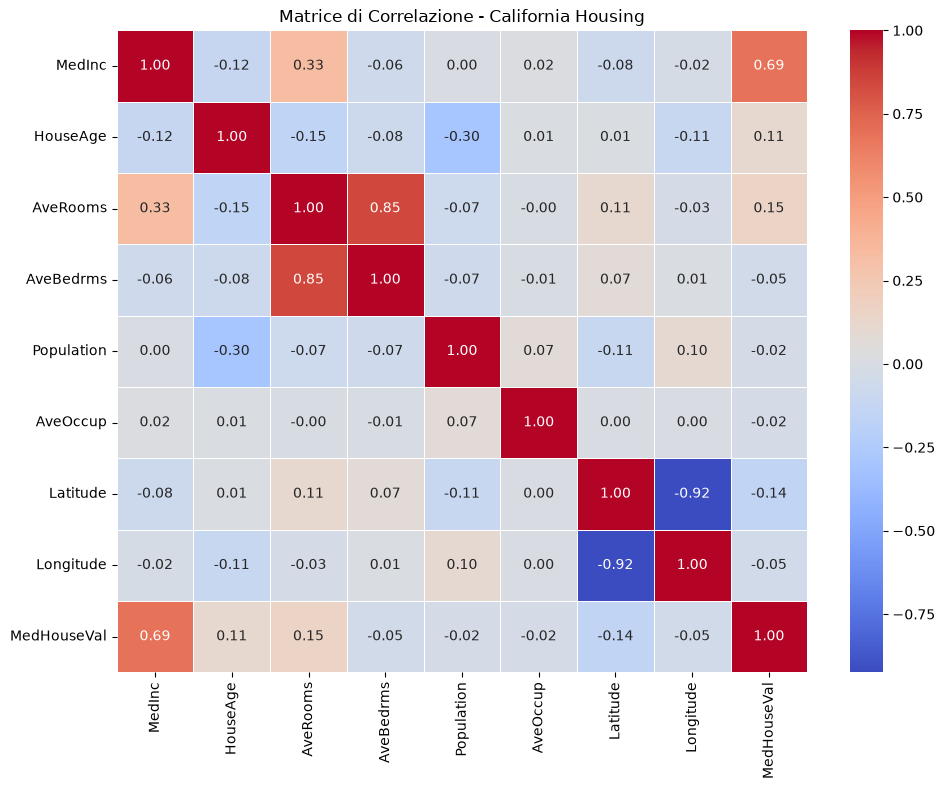

In [8]:
# ------------------------------------------------------------------------------
# PASSO 2: Analisi Esplorativa dei Dati (EDA)
# ------------------------------------------------------------------------------

#Calcolo della matrice di correlazione per vedere quali feature influenzano maggiormente MedHouseVal
print("\n--- PASSO 2: ANALISI CORRELAZIONE ---")
corr_matrix = df.corr() #calcolo della matrice di correlazione tra tutte le feature numeriche, per vedere quali feature
#influenzano maggiormente MedHouseVal
print("Correlazione di ogni feature con MedHouseVal:")
print(corr_matrix["MedHouseVal"].sort_values(ascending=False)) #stampa la correlazione
#di ogni feature con MedHouseVal in ordine decrescente

#Notiamo che MedInc ha la correlazione più alta con MedHouseVal, quindi il reddito medio del blocco è il 
#fattore più influente sul valore delle abitazioni.

# Generazione Heatmap di correlazione
plt.figure(figsize=(10, 8))
sns.heatmap(corr_matrix, annot=True, cmap="coolwarm", fmt=".2f", linewidths=0.5) #coolwarm è una mappa di colori che va dal blu (bassa correlazione) al rosso (alta correlazione)
plt.title("Matrice di Correlazione - California Housing") #fmt serve a formattare i valori numerici nella heatmap con 2 decimali e linewidths serve a separare le celle della heatmap con linee sottili
plt.tight_layout() #serve a ottimizzare il layout della figura per evitare sovrapposizioni di elementi
plt.savefig("correlazione_features.png") 
plt.show()


In [ ]:
# ------------------------------------------------------------------------------
# PASSO 3: Preparazione dei Dati (Features X, Target y, Train-Test Split)
# ------------------------------------------------------------------------------
print("\n--- PASSO 3: SEPARAZIONE DATI E TRAIN-TEST SPLIT ---")

#Separazione delle feature (X) e del target (y) al fine di addestrare il modello di regressione lineare, ovvero ad evitare l'overfitting.
#separiamo quindi il dataset in due parti (X(80%) e y(20%)) per addestrare il modello e testarlo su dati mai visti prima.
X = df.drop(columns=["MedHouseVal"]) #tutte le colonne tranne MedHouseVal sono feature (X)
y = df["MedHouseVal"] # MedHouseVal è il target (y)

# Dividiamo in training (80%) e test (20%). random_state fissa la casualita'
# dello shuffle, cosi' lo split e' identico ogni volta che eseguiamo la cella.
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE
)

print(f"Dimensioni Training Set (X_train): {X_train.shape}")
print(f"Dimensioni Test Set (X_test):     {X_test.shape}")
#oppure
print("Immobili nel training set:", len(X_train))
print("Immobili nel test set:    ", len(X_test))

# Standardizzazione delle Feature (Feature Scaling)
# Nota: Si applica fit_transform su Train e solo transform su Test per evitare Data Leakage
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)
#serve a standardizzare le feature, ovvero a portarle tutte su una scala simile (media=0, deviazione standard=1)
#per migliorare la performance del modello di regressione lineare.







--- PASSO 3: SEPARAZIONE DATI E TRAIN-TEST SPLIT ---
Dimensioni Training Set (X_train): (16512, 8)
Dimensioni Test Set (X_test):     (4128, 8)
Immobili nel training set: 16512
Immobili nel test set:     4128


In [ ]:
# ------------------------------------------------------------------------------
# PASSO 4: Addestramento del Modello (Regressione Lineare)
# ------------------------------------------------------------------------------
#Creazione e fit del modello LinearRegression() sui dati di addestramento scalati ($X_{train\_scaled}, y_{train}$).
print("\n--- PASSO 4: ADDESTRAMENTO REGRESSIONE LINEARE ---")

model = LinearRegression()
model.fit(X_train_scaled, y_train)

# Stampa dell'Intercetta e dei Coefficienti appresi
print(f"Intercetta (Bias) del modello: {model.intercept_:.4f}")
print("\nCoefficienti attribuiti a ciascuna Feature:")
for col, coef in zip(X.columns, model.coef_): 
  print(f"  - {col:12s}: {coef:.4f}")
#scopriamo quali feature hanno maggiore impatto sul target MedHouseVal in base ai coefficienti del modello di regressione lineare.



--- PASSO 4: ADDESTRAMENTO REGRESSIONE LINEARE ---
Intercetta (Bias) del modello: 2.0719

Coefficienti attribuiti a ciascuna Feature:
  - MedInc      : 0.8544
  - HouseAge    : 0.1225
  - AveRooms    : -0.2944
  - AveBedrms   : 0.3393
  - Population  : -0.0023
  - AveOccup    : -0.0408
  - Latitude    : -0.8969
  - Longitude   : -0.8698


In [23]:
# ------------------------------------------------------------------------------
# PASSO 5: Valutazione del Modello e Predizione
# ------------------------------------------------------------------------------
print("\n--- PASSO 5: VALUTAZIONE PREDIZIONI ---")

# Predizioni sul Test Set
y_pred = model.predict(X_test_scaled)
# Calcolo delle Metriche di Valutazione
mae = mean_absolute_error(y_test, y_pred) # Errore Assoluto Medio
mse = mean_squared_error(y_test, y_pred) # Errore Quadratico Medio
rmse = np.sqrt(mse) # Radice dell'Errore Quadratico Medio
r2 = r2_score(y_test, y_pred) * 100 # Coefficiente di Determinazione
print(f"MAE  (Mean Absolute Error):      {mae:.4f} ($ {mae*100000:.2f})")
print(f"MSE  (Mean Squared Error):       {mse:.4f} ($ {mse*100000:.2f})")
print(f"RMSE (Root Mean Squared Error):  {rmse:.4f} ($ {rmse*100000:.2f})")
print(f"R² Score (Coeff. Determinaz.):   {r2:.2f}%")




--- PASSO 5: VALUTAZIONE PREDIZIONI ---
MAE  (Mean Absolute Error):      0.5332 ($ 53320.01)
MSE  (Mean Squared Error):       0.5559 ($ 55589.16)
RMSE (Root Mean Squared Error):  0.7456 ($ 74558.14)
R² Score (Coeff. Determinaz.):   57.58%


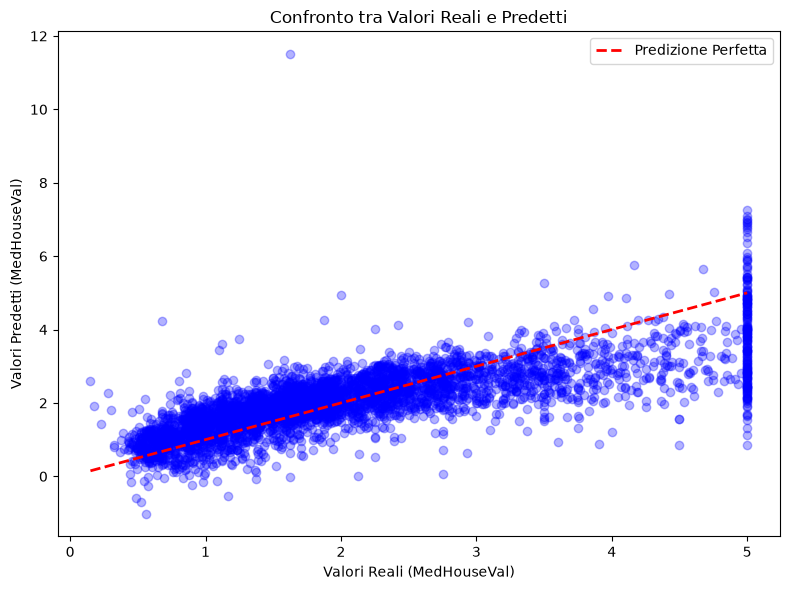

In [14]:
# ------------------------------------------------------------------------------
# PASSO 6: Visualizzazione Grafica dei Risultati
# ------------------------------------------------------------------------------
# Grafico Valori Reali vs Valori Predetti
plt.figure(figsize=(8, 6))
plt.scatter(y_test, y_pred, alpha=0.3, color="blue")
plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    "r--",
    lw=2,
    label="Predizione Perfetta",
)
plt.xlabel("Valori Reali (MedHouseVal)")
plt.ylabel("Valori Predetti (MedHouseVal)")
plt.title("Confronto tra Valori Reali e Predetti")
plt.legend()
plt.tight_layout()
plt.savefig("reali_vs_predetti.png")
plt.show()